# IDM calibration on the Interstate 695 sample

This notebook calibrates the Intelligent Driver Model (IDM) on one vehicle of `Snowy_I-695_Sample01.csv` with a genetic algorithm (GA), following `Guidelines for Calibrating Car-Following Models.pdf`. Run it from the `Data/` folder, since it reads the CSV by relative path.

`DT` below is the only time step in the notebook. Every trajectory is resampled to it, and the IDM is integrated with it. The guideline uses a 0.2 s sampling rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sko.GA import GA

DT = 0.2             # s, resampling step of the trajectories and IDM integration step
FOLLOWER_ID = 104    # vehicle whose car-following behavior is calibrated
SEED = 0             # random seed of the GA, for a reproducible run

## Load the trajectories

Each track ends with one row that has only `Vehicle ID` and `Type` filled, and `dropna()` removes it. The heading column is named `' Angle [rad]'`, and the `Type` values also start with a space, which the notebook strips.

In [2]:
df = pd.read_csv("Snowy_I-695_Sample01.csv")
df = df.dropna().copy()
df['x [m]'] = pd.to_numeric(df['x [m]'], errors='coerce')
df['Type'] = df['Type'].str.strip()
df['speed'] = df['Speed [km/h]'] / 3.6   # m/s
print(df['Type'].value_counts())
print(f"{df['Vehicle ID'].nunique()} vehicles, maximum speed {df['speed'].max():.2f} m/s")

Type
Car               36961
Medium Vehicle     2503
Heavy Vehicle      1796
Name: count, dtype: int64
113 vehicles, maximum speed 15.74 m/s


## Road coordinates and lanes

The CSV has no lane column. The notebook projects every position onto the mean heading of all vehicles. This gives a longitudinal position `s` along the road and a lateral offset `d` across it. The segment is close to straight, so this projection follows the road. The printed percentiles show how far the vehicles spread across the road.

The leader search below is lane-aware through `d`: a vehicle counts as a leader only if its lateral offset is within half a lane width of the follower's. `LANE_WIDTH` is 3.66 m (12 ft), the standard Interstate lane width in the US. It is an assumption, not a value from the data.

In [3]:
LANE_WIDTH = 3.66   # m, assumed lane width (12 ft)

heading = np.arctan2(np.sin(df[' Angle [rad]']).mean(), np.cos(df[' Angle [rad]']).mean())
x_rel = df['x [m]'] - df['x [m]'].min()
y_rel = df['y [m]'] - df['y [m]'].min()
df['s'] = x_rel * np.cos(heading) + y_rel * np.sin(heading)    # longitudinal position (m)
df['d'] = -x_rel * np.sin(heading) + y_rel * np.cos(heading)   # lateral offset (m)

print(f"mean heading {heading:.4f} rad, segment length {df['s'].max() - df['s'].min():.1f} m")
print("lateral offset percentiles (1, 5, 50, 95, 99) in m:", np.round(np.percentile(df['d'], [1, 5, 50, 95, 99]), 2))

mean heading 0.8459 rad, segment length 129.4 m
lateral offset percentiles (1, 5, 50, 95, 99) in m: [-0.64 -0.24  0.32  0.79  0.95]


## Vehicle lengths

The CSV has no length column, so the notebook assigns a nominal length by `Type`. These lengths are assumptions. The notebook treats the recorded position as the center of the vehicle, so the front bumper is at `s + length / 2` and the rear bumper at `s - length / 2`.

In [4]:
VEHICLE_LENGTH = {'Car': 5.0, 'Medium Vehicle': 8.0, 'Heavy Vehicle': 16.0}   # m, assumed
df['length'] = df['Type'].map(VEHICLE_LENGTH)
assert df['length'].notna().all(), 'a Type without a length in VEHICLE_LENGTH'


## Resample every vehicle to a fixed step

The recording has about 30 frames per second, and all vehicles share the same frame time stamps. Each vehicle's own trajectory is interpolated onto the common time grid `k * DT`. This gives every vehicle a constant step of `DT`, and the vehicles stay aligned in time, so the leader search can compare them step by step.

In [5]:
COLUMNS = ['s', 'd', 'speed', 'Tan. Acc. [ms-2]']

def resample_vehicle(vehicle_id, g):
    t = g['Time [s]'].to_numpy()
    steps = np.arange(np.ceil(t[0] / DT - 1e-9), np.floor(t[-1] / DT + 1e-9) + 1).astype(int)
    t_grid = steps * DT
    out = pd.DataFrame({'Vehicle ID': vehicle_id, 'step': steps, 'time': t_grid})
    for col in COLUMNS:
        out[col] = np.interp(t_grid, t, g[col].to_numpy())
    out['Type'] = g['Type'].iloc[0]
    out['length'] = g['length'].iloc[0]
    return out

df_rs = pd.concat([resample_vehicle(vid, g.sort_values('Time [s]'))
                   for vid, g in df.groupby('Vehicle ID')], ignore_index=True)
print(f"{len(df)} rows at the recording rate, {len(df_rs)} rows at DT = {DT} s")

41260 rows at the recording rate, 6870 rows at DT = 0.2 s


## Leader search

At each step, the leader of a vehicle is the nearest vehicle ahead of it in `s` whose lateral offset is within `LANE_WIDTH / 2` of its own. The gap is the distance from the follower's front bumper to the leader's rear bumper.

In [6]:
def find_leaders(group):
    ids = group['Vehicle ID'].to_numpy()
    s = group['s'].to_numpy()
    d = group['d'].to_numpy()
    half = group['length'].to_numpy() / 2
    speed = group['speed'].to_numpy()

    front = s + half
    rear = s - half
    ahead = s[None, :] > s[:, None]                                  # j is ahead of i
    same_lane = np.abs(d[None, :] - d[:, None]) < LANE_WIDTH / 2
    gap = np.where(ahead & same_lane, rear[None, :] - front[:, None], np.inf)
    dist = np.where(ahead & same_lane, s[None, :] - s[:, None], np.inf)

    j = np.argmin(dist, axis=1)
    has_leader = np.isfinite(dist[np.arange(len(ids)), j])
    group = group.copy()
    group['leading_vehicle'] = np.where(has_leader, ids[j], -1)
    group['gap'] = np.where(has_leader, gap[np.arange(len(ids)), j], np.nan)
    group['leading_vehicle_speed'] = np.where(has_leader, speed[j], np.nan)
    return group

df1 = pd.concat([find_leaders(g) for _, g in df_rs.groupby('step')], ignore_index=True)
df1['Vehicle ID'].unique()

array([  1,  15,  16,  23,  24,  28,  32,  38,  44,  52,  58,  30,  66,
        72,  77,  84,  88,  97, 104, 110, 112, 122, 132, 128, 133, 138,
       145, 152, 155, 160, 169, 175, 183, 191, 199, 203, 213, 220, 229,
       234, 239, 250, 258, 264, 268, 273, 281, 285, 296, 307, 315, 327,
       333, 338, 342, 345, 355, 361, 368, 378, 387, 395, 399, 416, 423,
       432, 443, 447, 453, 460, 470, 481, 491, 497, 504, 512, 519, 542,
       551, 560, 567, 571, 581, 588, 593, 596, 600, 603, 606, 613, 620,
       624, 628, 639, 649, 657, 663, 671, 680, 686, 693, 702, 709, 715,
       721, 730, 735, 744, 748, 758, 769, 779, 787])

## Car-following pair

The calibration uses the longest run of consecutive steps in which `FOLLOWER_ID` follows the same leader. The leader position used by the IDM is the leader's rear bumper, and the follower position is the follower's front bumper, so their difference is the gap.

In [7]:
veh = df1[df1['Vehicle ID'] == FOLLOWER_ID].sort_values('step').copy()
run_id = ((veh['leading_vehicle'] != veh['leading_vehicle'].shift())
          | (veh['step'].diff() != 1)).cumsum()
veh = veh[veh['leading_vehicle'] >= 0]
longest = veh.groupby(run_id[veh.index]).size().idxmax()
veh = veh[run_id[veh.index] == longest].copy()

veh['follower_front'] = veh['s'] + veh['length'] / 2
veh['leading_vehicle_location'] = veh['follower_front'] + veh['gap']   # leader rear bumper
print(f"vehicle {FOLLOWER_ID} follows vehicle {int(veh['leading_vehicle'].iloc[0])} "
      f"for {len(veh)} steps ({(len(veh) - 1) * DT:.1f} s), maximum speed {veh['speed'].max():.2f} m/s")

vehicle 104 follows vehicle 97 for 63 steps (12.4 s), maximum speed 11.44 m/s


## IDM and GA calibration

The IDM acceleration is

$$\frac{dv_n}{dt} = a\left[1-\left(\frac{v_n}{v_0}\right)^{\delta}-\left(\frac{s^{*}}{s_n}\right)^{2}\right], \qquad s^{*} = s_0 + \max\left(0,\ v_n T + \frac{v_n\,\Delta v_n}{2\sqrt{ab}}\right),$$

with $\delta = 4$. The simulation starts from the recorded position and speed of the follower and replays the recorded leader. At each step the acceleration is computed from the state at the previous step, and the speed is clipped at zero. The same simulation is used for calibration and for evaluation.

The GA minimizes the root mean square error (RMSE) of the gap between the recorded and the simulated follower. The bounds follow the guideline. The lower bound of $v_0$ must exceed the highest speed observed in the data, so it is the maximum speed of the whole sample rounded up to the next m/s, and the upper bound is 33.6 m/s (120 km/h).

In [8]:
def idm(xLead, vLead, xFoll, vFoll, model_params):
    s0 = model_params['s0']
    T = model_params['T']
    a = model_params['a']
    b = model_params['b']
    v0 = model_params['v0']
    delta = 4

    s_star = s0 + max(0, vFoll * T + vFoll * (vFoll - vLead) / (2 * np.sqrt(a * b)))
    gap = max(xLead - xFoll, 0.1)   # keeps the interaction term finite
    return a * (1 - (vFoll / v0)**delta - (s_star / gap)**2)


def run_simulation(model_params, xLead, vLead, xFollInitial, vFollInitial, dt, num_steps):
    xFoll = [xFollInitial]
    vFoll = [vFollInitial]
    for t in range(1, num_steps):
        acc = idm(xLead[t - 1], vLead[t - 1], xFoll[t - 1], vFoll[t - 1], model_params)
        new_vFoll = max(0.0, vFoll[t - 1] + acc * dt)
        new_xFoll = xFoll[t - 1] + (vFoll[t - 1] + new_vFoll) * dt / 2
        vFoll.append(new_vFoll)
        xFoll.append(new_xFoll)
    return np.array(xFoll), np.array(vFoll)


def gap_rmse(model_params, xLead, vLead, xFollInitial, vFollInitial, dt, num_steps, xReal):
    xSim, _ = run_simulation(model_params, xLead, vLead, xFollInitial, vFollInitial, dt, num_steps)
    # xLead is shared, so the position error equals the gap error
    return np.sqrt(np.mean((xReal - xSim)**2))


# Recorded leader and follower
xLead_real = veh['leading_vehicle_location'].to_numpy()
vLead_real = veh['leading_vehicle_speed'].to_numpy()
xFoll_real = veh['follower_front'].to_numpy()
xFollInitial = xFoll_real[0]
vFollInitial = veh['speed'].iloc[0]   # recorded initial speed of the follower
num_steps = len(veh)

V0_LOWER = float(np.ceil(df['speed'].max()))
IDM_param_bounds = {'s0': (1, 5), 'T': (0.1, 3), 'a': (0.1, 4), 'b': (0.1, 9), 'v0': (V0_LOWER, 33.6)}
print("bounds:", IDM_param_bounds)


def fitness_idm(model_params):
    params = dict(zip(IDM_param_bounds, model_params))
    return gap_rmse(params, xLead_real, vLead_real, xFollInitial, vFollInitial, DT, num_steps, xFoll_real)


np.random.seed(SEED)
idmga = GA(func=fitness_idm,
           n_dim=5,
           size_pop=100,
           max_iter=200,
           prob_mut=0.05,
           lb=[IDM_param_bounds[key][0] for key in IDM_param_bounds],
           ub=[IDM_param_bounds[key][1] for key in IDM_param_bounds])
idmbest_params, idmbest_rmse = idmga.run()

bounds: {'s0': (1, 5), 'T': (0.1, 3), 'a': (0.1, 4), 'b': (0.1, 9), 'v0': (16.0, 33.6)}


In [9]:
idmoptimized_params = {key: float(idmbest_params[i]) for i, key in enumerate(IDM_param_bounds)}
print("IDM optimized parameters:", {k: round(v, 3) for k, v in idmoptimized_params.items()})
print(f"IDM best gap RMSE: {float(np.ravel(idmbest_rmse)[0]):.4f} m")

IDM optimized parameters: {'s0': 3.68, 'T': 0.293, 'a': 1.15, 'b': 1.646, 'v0': 23.585}
IDM best gap RMSE: 0.1690 m


## Evaluation

The calibrated parameters are run through the same simulation. The simulated acceleration is the finite difference of the simulated speed. The recorded acceleration is the tangential acceleration column of the CSV.

In [10]:
xFollSim_idm, vFollSim_idm = run_simulation(idmoptimized_params, xLead_real, vLead_real,
                                            xFollInitial, vFollInitial, DT, num_steps)
aFollSim_idm = np.append(np.diff(vFollSim_idm) / DT, np.nan)   # no forward difference at the last step
gap_sim_idm = xLead_real - xFollSim_idm

vFoll_real = veh['speed'].to_numpy()
aFoll_real = veh['Tan. Acc. [ms-2]'].to_numpy()
gap_real = veh['gap'].to_numpy()
time_array = np.arange(num_steps) * DT
print(f"gap RMSE of the evaluation run: {np.sqrt(np.mean((gap_real - gap_sim_idm)**2)):.4f} m")

gap RMSE of the evaluation run: 0.1690 m


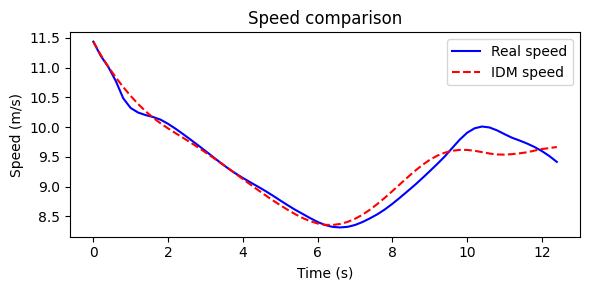

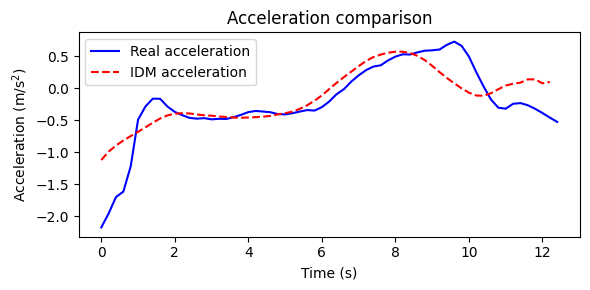

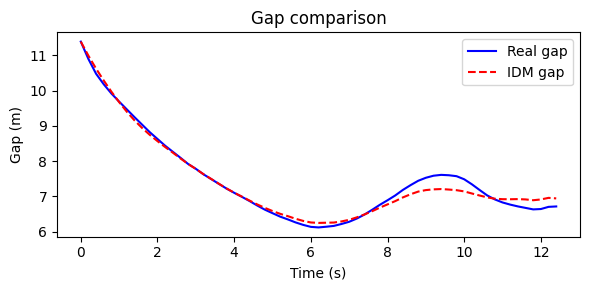

In [11]:
def comparison_plot(real, sim, ylabel, title, path=None):
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(time_array, real, label=f'Real {title.lower()}', color='blue')
    ax.plot(time_array, sim, label=f'IDM {title.lower()}', color='red', linestyle='dashed')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title} comparison')
    ax.legend()
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=150)
    plt.show()


comparison_plot(vFoll_real, vFollSim_idm, 'Speed (m/s)', 'Speed')
comparison_plot(aFoll_real, aFollSim_idm, 'Acceleration (m/s$^2$)', 'Acceleration')
comparison_plot(gap_real, gap_sim_idm, 'Gap (m)', 'Gap', path='../docs/img/idm_calibration_gap.png')